# Part 5 — Open-ended retrieval challenge: *motorbike* retrieval
**Task.** Given a query (image or text) rank a fixed corpus so that motorbike images come first. No classifier is trained.
* **Corpus** = the whole provided `val` split (2474 images; 125 relevant = `motorbike_val`; irrelevant ones include `person`, `car`, `horse` and `background` images, i.e. hard negatives such as cars and riders).
* **Queries** = motorbike images from the `train` split (disjoint from the corpus, so no exact duplicates), selected **without looking at corpus labels**: k-means (k=10) on DINOv2 features of the train motorbikes, the image closest to each centroid. Near-duplicates were not exhaustively checked (limitation).
* **Ground truth** = split membership `motorbike_val`. Images that contain a motorbike but are only labelled `person` are counted as irrelevant (incomplete ground truth, see limitations).
* **Methods**: BoVW, VLAD, Fisher Vector (provided encodings, cosine), ResNet-18 / ViT-B/32 / DINOv2 embeddings (cosine), CLIP image->image and CLIP text->image. Metrics: AP, P@5/10/20, R@K, timing, storage.

In [3]:
import time, warnings, glob
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import torch
warnings.filterwarnings("ignore")
from src import eval as ev
from src.deep_models import getModel

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "data" / "images").exists())
DATA = str(ROOT / "data"); FEAT = ROOT / "data" / "features"; RES = ROOT / "code" / "results"; RES.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
table = ev.split_table(DATA); names = table.name.values
CAT = "motorbike"
corpus = np.where((table.split == "val").values)[0]
rel = table[CAT].values[corpus]
print(f"device {device} | corpus {len(corpus)} images, {rel.sum()} relevant ({rel.mean():.1%})")

def deep(model, key):
    f = FEAT / f"{model}.npz"
    assert f.exists(), "run 2_deep_models.ipynb first (it caches the embeddings in data/features/)"
    z = np.load(f, allow_pickle=True); assert (z["names"] == names).all()
    return z[key], float(z["sec_per_img"])

def enc_matrix(enc):
    d = {}
    for c in ev.ALL_CATS:
        for sp in ("train", "val"):
            z = np.load(f"{DATA}/encodings/{enc}/{c}_{sp}.npz"); d.update(zip(map(str, z["file_names"]), z["histograms"]))
    return np.stack([d[str(n)] for n in names])

device mps | corpus 2474 images, 125 relevant (5.1%)


## Stage A — Queries (diverse set, label-free w.r.t. the corpus)

query images: ['002795', '009004', '001450', '009756', '008676', '005414', '000685', '000987', '004882', '006177']


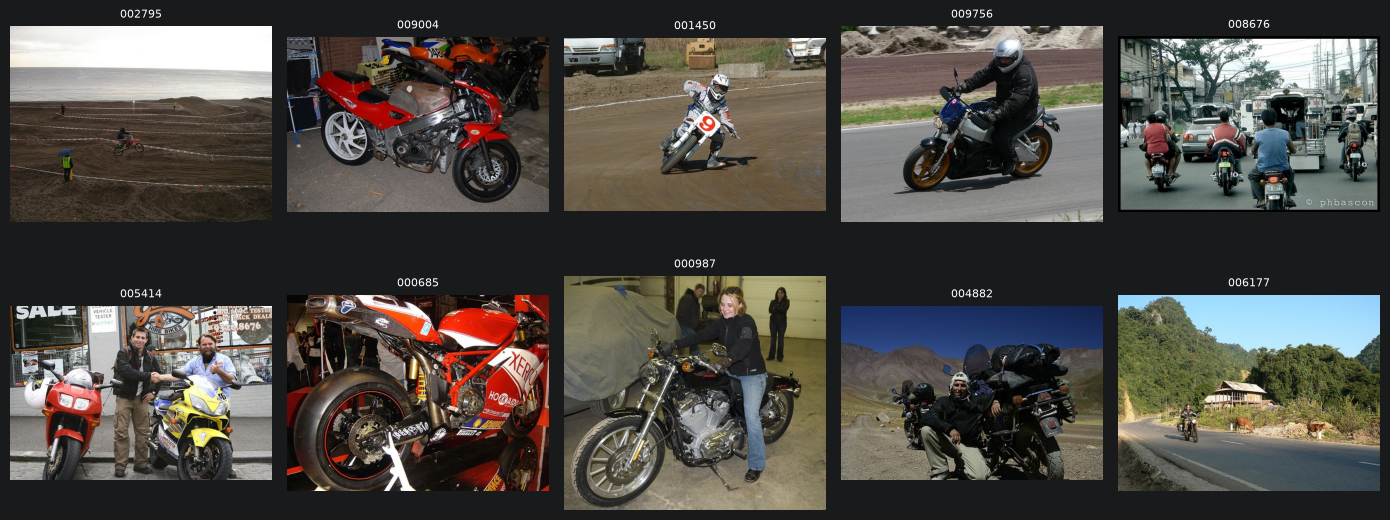

In [4]:
from sklearn.cluster import KMeans
Fd, sec_dino = deep("dinov2_vits14", "dinov2_cls")
tr_pos = np.where((table.split == "train").values & table[CAT].values)[0]
km = KMeans(10, n_init=10, random_state=0).fit(ev.l2(Fd[tr_pos]))
queries = np.array([tr_pos[np.argmin(((ev.l2(Fd[tr_pos]) - c) ** 2).sum(1))] for c in km.cluster_centers_])
print("query images:", list(names[queries]))
fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for a, q in zip(ax.ravel(), queries): a.imshow(Image.open(f"{DATA}/images/{names[q]}.jpg")); a.axis("off"); a.set_title(names[q], fontsize=8)
plt.tight_layout(); plt.show()

## Stage B/C — Image-query retrieval with all feature types

In [5]:
KS = (5, 10, 20); RK = (10, 50, 100)
def metrics(s, rel):
    out = dict(AP=ev.ap(rel * 2 - 1, s))
    out.update({f"P@{k}": ev.precision_at_k(rel * 2 - 1, s, k) for k in KS}); out.update({f"R@{k}": ev.recall_at_k(rel * 2 - 1, s, k) for k in RK})
    return out

def run_method(name, Fm, norm, extract_ms, queries=queries, pca=0):
    Xc, Xq = ev.NORMS[norm](Fm[corpus]), ev.NORMS[norm](Fm[queries])
    if pca:   # PCA fitted on the TRAIN split only (the corpus is val)
        from sklearn.decomposition import PCA
        t0 = time.perf_counter(); p = PCA(pca, random_state=0).fit(ev.NORMS[norm](Fm[(table.split == "train").values])); t_pca = time.perf_counter() - t0
        Xc, Xq = ev.l2(p.transform(Xc)), ev.l2(p.transform(Xq))
    else: t_pca = 0.0
    t0 = time.perf_counter(); S = Xq @ Xc.T; _ = np.argsort(-S, axis=1); t_rank = (time.perf_counter() - t0) / len(Xq)
    per_q = pd.DataFrame([metrics(s, rel) for s in S])
    row = dict(method=name, dim=Xc.shape[1], mAP=per_q.AP.mean(), **{c: per_q[c].mean() for c in per_q.columns if c != "AP"}, AP_std_over_queries=per_q.AP.std(),
               extract_ms_per_img=extract_ms, rank_ms_per_query=1e3 * t_rank, corpus_MB=Xc.astype(np.float32).nbytes / 2**20, pca_fit_s=t_pca)
    return row, per_q, S

F_bovw = enc_matrix("bovw_K512_C0")
METHODS = [("BoVW K512", F_bovw, "hellinger", np.nan, 0), ("VLAD K32 PCA80", enc_matrix("vlad_K32_C80"), "ssqrt_l2", np.nan, 0),
           ("FV K32 PCA80", enc_matrix("fv_K32_C80"), "ssqrt_l2", np.nan, 0)]
for model, key, label in (("resnet18", "resnet18_gap3", "ResNet-18 GAP3"), ("vit_b_32", "vit_b_32_cls", "ViT-B/32 CLS"), ("dinov2_vits14", "dinov2_cls", "DINOv2 CLS"), ("clip_vit_b_32", "clip_img", "CLIP image->image")):
    Fm, sec = deep(model, key); METHODS.append((label, Fm, "l2", 1e3 * sec, 0))
METHODS += [("BoVW K512 + PCA128", F_bovw, "hellinger", np.nan, 128), ("BoVW K512 + PCA256", F_bovw, "hellinger", np.nan, 256),
            ("DINOv2 CLS + PCA64", Fd, "l2", 1e3 * sec_dino, 64)]
# other vocabulary sizes (K=256/1024), if their encodings were generated with cyvlfeat (see README), are picked up here
for e in sorted({Path(p).name for p in glob.glob(f"{DATA}/encodings/bovw_K*_C0")} - {"bovw_K512_C0"}):
    METHODS.append((e.replace("_C0", ""), enc_matrix(e), "hellinger", np.nan, 0))
RESULTS, PERQ, SCORES = [], {}, {}
for name, Fm, norm, ms, pca in METHODS:
    row, pq, S = run_method(name, Fm, norm, ms, pca=pca); RESULTS.append(row); PERQ[name] = pq; SCORES[name] = S
R5 = pd.DataFrame(RESULTS).set_index("method"); display(R5.round(3)); R5.to_csv(RES / "part5_image_queries.csv")
pd.DataFrame({k: v.AP for k, v in PERQ.items()}).round(3).to_csv(RES / "part5_per_query_AP.csv")

,dim,mAP,P@5,P@10,P@20,R@10,R@50,R@100,AP_std_over_queries,extract_ms_per_img,rank_ms_per_query,corpus_MB,pca_fit_s
method,,,,,,,,,,,,,
BoVW K512,2048,0.125,0.40,0.32,0.260,0.026,0.079,0.134,0.046,NaN,0.605,19.328,0.000
VLAD K32 PCA80,10240,0.124,0.42,0.34,0.250,0.027,0.079,0.130,0.045,NaN,0.432,96.641,0.000
FV K32 PCA80,20608,0.084,0.30,0.25,0.175,0.020,0.050,0.082,0.036,NaN,0.980,194.489,0.000
ResNet-18 GAP3,896,0.578,0.76,0.75,0.730,0.060,0.279,0.482,0.273,3.508,0.230,8.456,0.000
ViT-B/32 CLS,768,0.665,0.76,0.75,0.770,0.060,0.302,0.561,0.282,5.459,0.239,7.248,0.000
DINOv2 CLS,384,0.611,0.90,0.86,0.830,0.069,0.290,0.522,0.283,7.560,0.100,3.624,0.000
CLIP image->image,512,0.483,0.80,0.76,0.745,0.061,0.261,0.393,0.269,6.224,0.103,4.832,0.000
BoVW K512 + PCA128,128,0.110,0.36,0.32,0.250,0.026,0.068,0.120,0.040,NaN,0.091,1.208,0.135
BoVW K512 + PCA256,256,0.110,0.40,0.32,0.275,0.026,0.069,0.118,0.039,NaN,0.095,2.416,0.130


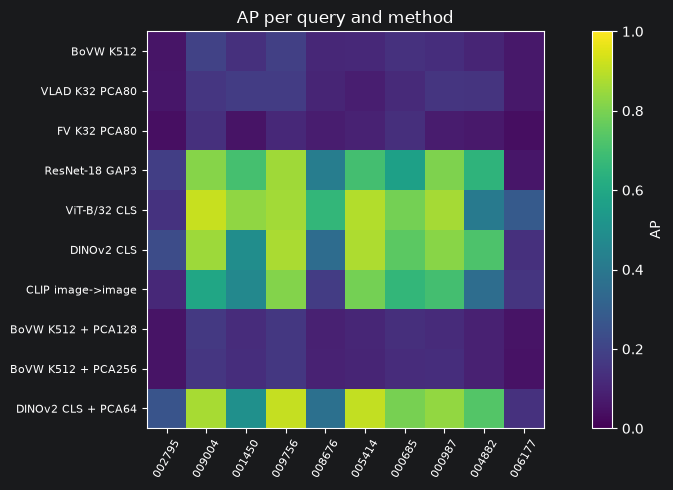

In [6]:
# per-query AP heat-map: which queries are easy / hard for which method
M = pd.DataFrame({k: v.AP.values for k, v in PERQ.items()}, index=[names[q] for q in queries]).T
fig, ax = plt.subplots(figsize=(10, 5)); im = ax.imshow(M.values, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=60, fontsize=8); ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=8)
plt.colorbar(im, label="AP"); ax.set_title("AP per query and method"); plt.tight_layout(); plt.show()

### Top-ranked results (successes and failures)
Green border = relevant, red = irrelevant. Best and worst query for DINOv2 and BoVW.

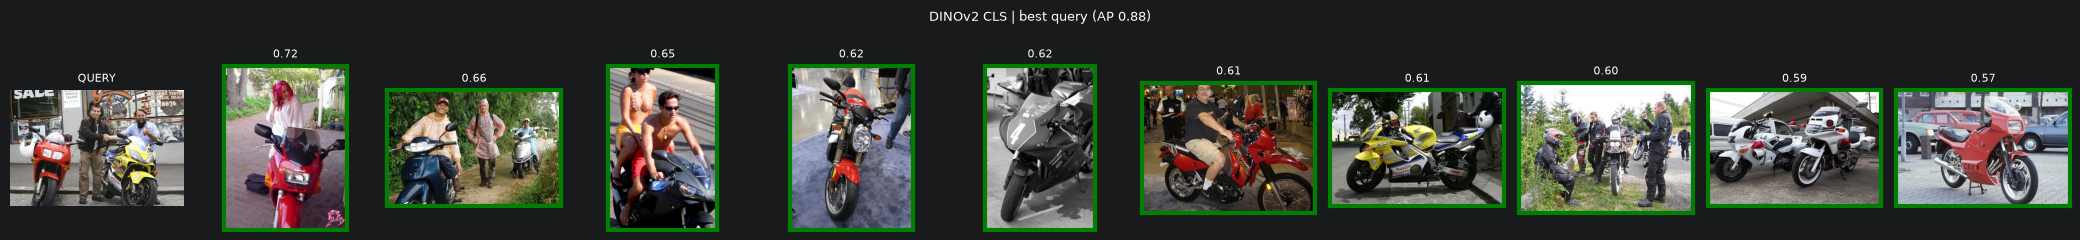

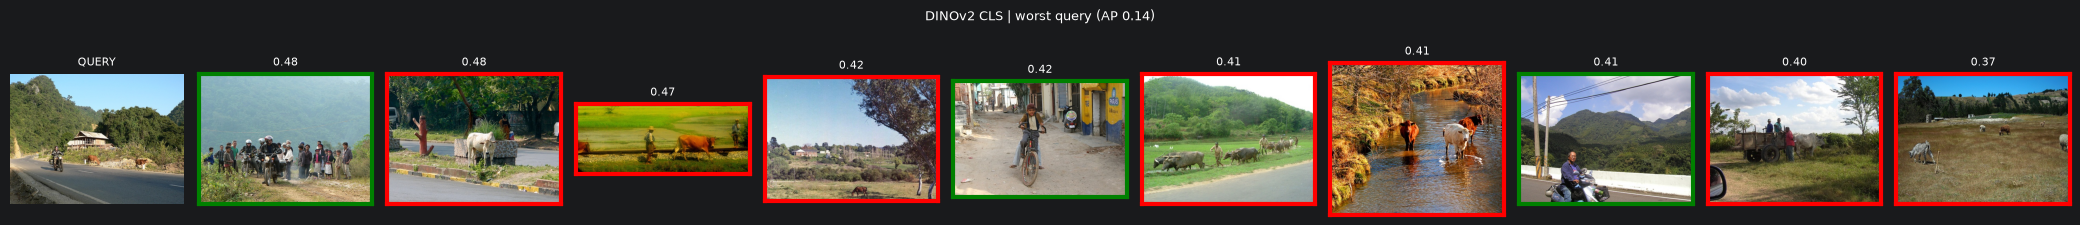

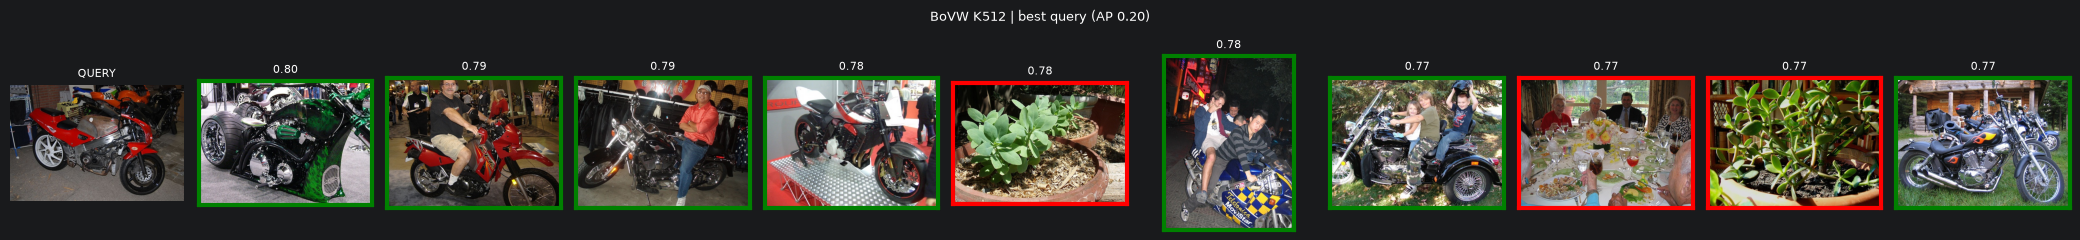

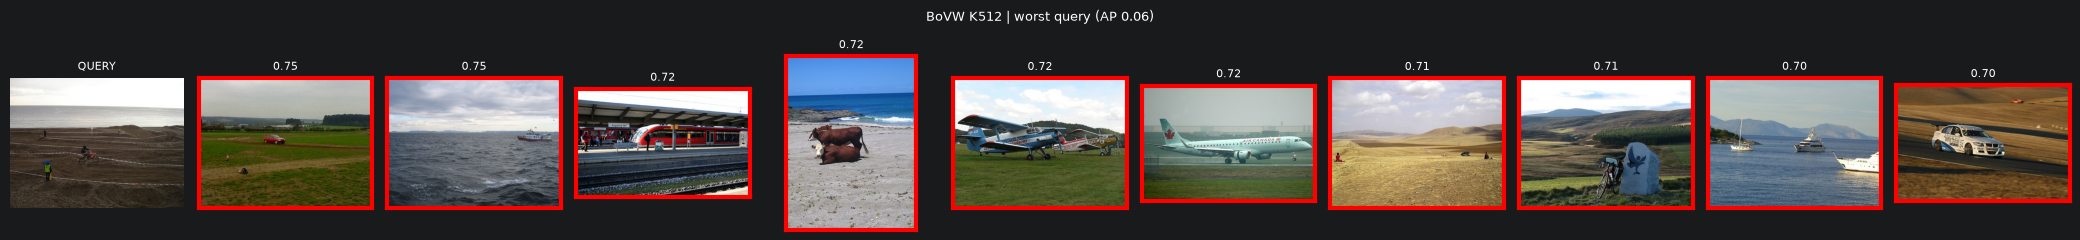

In [7]:
def show_topk(S_row, title, k=10, q=None):
    order = np.argsort(-S_row)[:k]
    fig, ax = plt.subplots(1, k + (q is not None), figsize=(1.9 * (k + 1), 2.4)); ax = np.atleast_1d(ax); j0 = 0
    if q is not None:
        ax[0].imshow(Image.open(f"{DATA}/images/{names[q]}.jpg")); ax[0].set_title("QUERY", fontsize=8); ax[0].axis("off"); j0 = 1
    for a, i in zip(ax[j0:], order):
        a.imshow(Image.open(f"{DATA}/images/{names[corpus[i]]}.jpg")); a.set_xticks([]); a.set_yticks([])
        for sp in a.spines.values(): sp.set_edgecolor("green" if rel[i] else "red"); sp.set_linewidth(3)
        a.set_title(f"{S_row[i]:.2f}", fontsize=8)
    fig.suptitle(title, fontsize=9); plt.tight_layout(); plt.show()

for m in ("DINOv2 CLS", "BoVW K512"):
    ap_q = PERQ[m].AP.values
    for tag, qi in (("best", int(ap_q.argmax())), ("worst", int(ap_q.argmin()))):
        show_topk(SCORES[m][qi], f"{m} | {tag} query (AP {ap_q[qi]:.2f})", q=queries[qi])

## Query diversity and query-set sensitivity (DINOv2 CLS)
Single random queries vs the diverse k-means set vs the 5 most similar queries (nearest neighbours of one query), with score-level fusion (mean cosine over the query set).

In [8]:
Xc = ev.l2(Fd[corpus]); rng = np.random.default_rng(0)
def set_ap(q_idx):
    s = (ev.l2(Fd[q_idx]) @ Xc.T).mean(0); return ev.ap(rel * 2 - 1, s)
single = [set_ap([q]) for q in rng.choice(tr_pos, 30, replace=False)]
rows = [dict(query_set="1 random query (30 draws)", mean_AP=np.mean(single), std=np.std(single), min=min(single), max=max(single))]
for k in (3, 5, 10):
    v = [set_ap(rng.choice(tr_pos, k, replace=False)) for _ in range(30)]
    rows.append(dict(query_set=f"{k} random queries (30 draws)", mean_AP=np.mean(v), std=np.std(v), min=min(v), max=max(v)))
rows.append(dict(query_set="10 diverse (k-means) queries", mean_AP=set_ap(queries), std=np.nan, min=np.nan, max=np.nan))
sims = []
for q in queries:                                    # 5 most similar train motorbikes to a query (a *homogeneous* set)
    d_ = ev.l2(Fd[tr_pos]) @ ev.l2(Fd[q][None]).T; sims.append(set_ap(tr_pos[np.argsort(-d_[:, 0])[:5]]))
rows.append(dict(query_set="5 most-similar queries (kNN of each k-means query)", mean_AP=np.mean(sims), std=np.std(sims), min=min(sims), max=max(sims)))
QS = pd.DataFrame(rows); display(QS.round(3)); QS.to_csv(RES / "part5_query_sets.csv", index=False)

,query_set,mean_AP,std,min,max
0,1 random query (30 draws),0.692,0.244,0.053,0.909
1,3 random queries (30 draws),0.843,0.112,0.514,0.931
2,5 random queries (30 draws),0.899,0.048,0.715,0.938
3,10 random queries (30 draws),0.915,0.036,0.748,0.943
4,10 diverse (k-means) queries,0.938,NaN,NaN,NaN
5,5 most-similar queries (kNN of each k-means qu...,0.715,0.188,0.380,0.920


## Text->image retrieval with CLIP — wording sensitivity

,AP,P@5,P@10,P@20,R@10,R@50,R@100,ms
text,,,,,,,,
motorbike,0.881,1.0,1.0,1.00,0.080,0.384,0.704,553.508
motorcycle,0.875,1.0,1.0,1.00,0.080,0.392,0.648,15.176
a photo of a motorbike,0.863,1.0,1.0,0.90,0.080,0.360,0.688,6.585
a photo of a motorcycle,0.869,1.0,1.0,1.00,0.080,0.376,0.680,5.718
a photo of a red motorcycle parked on a street,0.574,1.0,1.0,0.90,0.080,0.280,0.448,7.116
a person riding a motorcycle on a road,0.782,1.0,0.9,0.95,0.072,0.352,0.640,6.228
a close-up of a motorcycle engine and wheel,0.491,0.6,0.7,0.60,0.056,0.208,0.424,6.084
a vehicle,0.112,0.2,0.1,0.05,0.008,0.024,0.056,5.476
a two-wheeled vehicle with an engine,0.550,0.8,0.6,0.55,0.048,0.264,0.472,6.457


best wording (diagnostic only, chosen with corpus labels -> do not report as a tuned result): motorbike


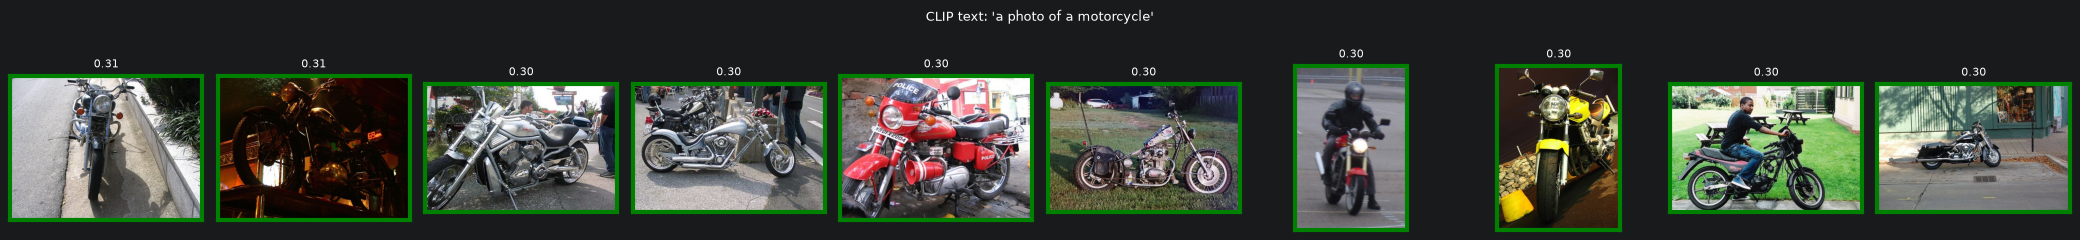

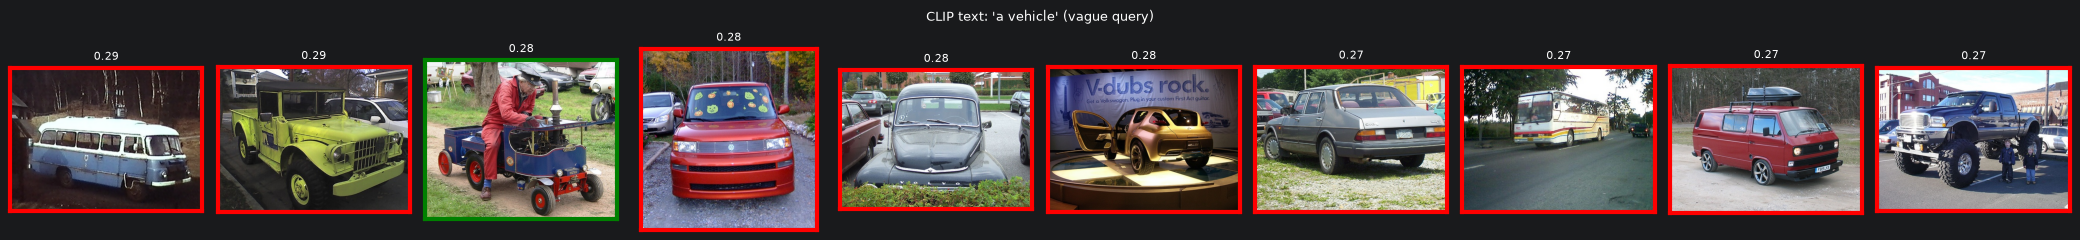

In [9]:
import clip
clip_model, _ = getModel("clip_vit_b_32", device=device)
Fc, sec_clip = deep("clip_vit_b_32", "clip_img"); Xcl = ev.l2(Fc[corpus])
def temb(t):
    with torch.inference_mode(): e = clip_model.encode_text(clip.tokenize([t]).to(device)).float().cpu().numpy()
    return ev.l2(e)[0]
QUERIES = ["motorbike", "motorcycle", "a photo of a motorbike", "a photo of a motorcycle", "a photo of a red motorcycle parked on a street",
           "a person riding a motorcycle on a road", "a close-up of a motorcycle engine and wheel", "a vehicle", "a two-wheeled vehicle with an engine", "a bicycle",
           "a photo of a car", "a photo of a horse"]
rows = []
for t in QUERIES:
    t0 = time.perf_counter(); s = Xcl @ temb(t); dt = time.perf_counter() - t0
    rows.append(dict(text=t, **metrics(s, rel), ms=1e3 * dt))
TX = pd.DataFrame(rows).set_index("text"); display(TX.round(3)); TX.to_csv(RES / "part5_clip_text.csv")
print("best wording (diagnostic only, chosen with corpus labels -> do not report as a tuned result):", TX.AP.idxmax())
show_topk(Xcl @ temb("a photo of a motorcycle"), "CLIP text: 'a photo of a motorcycle'")
show_topk(Xcl @ temb("a vehicle"), "CLIP text: 'a vehicle' (vague query)")

## Final retrieval summary

In [10]:
text_row = TX.loc["a photo of a motorbike"]
summary = R5[["dim", "mAP", "P@5", "P@10", "P@20", "R@50", "extract_ms_per_img", "rank_ms_per_query", "corpus_MB"]].copy()
summary.loc["CLIP text 'a photo of a motorbike' (1 query)"] = [512, text_row.AP, text_row["P@5"], text_row["P@10"], text_row["P@20"], text_row["R@50"], 1e3 * sec_clip, text_row.ms, Xcl.nbytes / 2**20]
display(summary.sort_values("mAP", ascending=False).round(3)); summary.to_csv(RES / "part5_summary.csv")
print(f"random-ranking baseline AP = prevalence = {rel.mean():.3f}")

,dim,mAP,P@5,P@10,P@20,R@50,extract_ms_per_img,rank_ms_per_query,corpus_MB
method,,,,,,,,,
CLIP text 'a photo of a motorbike' (1 query),512.0,0.863,1.00,1.00,0.900,0.360,6.224,6.585,4.832
ViT-B/32 CLS,768.0,0.665,0.76,0.75,0.770,0.302,5.459,0.239,7.248
DINOv2 CLS + PCA64,64.0,0.633,0.90,0.89,0.850,0.294,7.560,0.087,0.604
DINOv2 CLS,384.0,0.611,0.90,0.86,0.830,0.290,7.560,0.100,3.624
ResNet-18 GAP3,896.0,0.578,0.76,0.75,0.730,0.279,3.508,0.230,8.456
CLIP image->image,512.0,0.483,0.80,0.76,0.745,0.261,6.224,0.103,4.832
BoVW K512,2048.0,0.125,0.40,0.32,0.260,0.079,NaN,0.605,19.328
VLAD K32 PCA80,10240.0,0.124,0.42,0.34,0.250,0.079,NaN,0.432,96.641
BoVW K512 + PCA256,256.0,0.110,0.40,0.32,0.275,0.069,NaN,0.095,2.416


random-ranking baseline AP = prevalence = 0.051
